<div style="width: 100%; overflow: hidden;">
    <div style="width: 150px; float: left;"> <img src="data/D4Sci_logo_ball.png" alt="Data For Science, Inc" align="left" border="0"> </div>
    <div style="float: left; margin-left: 10px;"> <h1>Harness Engineering</h1>
<h1>01 - The AI Data Analyst</h1>
        <p>Bruno Gonçalves<br/>
        <a href="http://www.data4sci.com/">www.data4sci.com</a><br/>
            @bgoncalves, @data4sci</p></div>
</div>

In [1]:
from collections import Counter
from pprint import pprint
from pathlib import Path
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

import watermark

from harness.data import build_database
from harness.mcp_client import MCPClient
from harness.llm import MockAnalyst
from harness.agent import Agent, ToolBox, DEFAULT_SYSTEM_PROMPT
from harness.exercises import show_source, show_run, check_01

%load_ext watermark
%matplotlib inline

We start by print out the versions of the libraries we're using for future reference

In [2]:
%watermark -n -v -m -g -iv

Python implementation: CPython
Python version       : 3.13.13
IPython version      : 9.17.1

Compiler    : Clang 22.1.3 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 16
Architecture: 64bit

Git hash: f45998e2cfd5a6dc68ecdc40a669ed274dd25212

duckdb    : 1.5.6
json      : 2.0.9
matplotlib: 3.11.2
numpy     : 2.5.4
pandas    : 3.1.0
watermark : 2.6.0



Load default figure style

In [3]:
plt.style.use('d4sci.mplstyle')
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# The model is the smallest part of an agent

Over the next four hours we build an **AI data analyst**: you ask it a business question in plain English, it queries a database and writes you a report. Getting a model to do that *once* takes an afternoon. Getting it to do it in a way you can **trust** is what this workshop is about.

Everything around the model is the **harness**:

| Component | Question it answers | Notebook |
|:--|:--|:--:|
| Permissioned tools | What may the model touch, and who decides? | 02 |
| Context management | What does the model see, within a token budget? | 03 |
| Layered guardrails | What if the data itself is hostile? | 04 |
| Report verification | Why should anyone believe the numbers? | 05 |
| Run supervision | What happens when things break? | 06 |

No agent framework: every component is a few dozen lines of plain Python in the `harness/` package, so you can read, test and reuse all of it.

In this notebook we meet the data, the MCP server and the model, wire them together with a naive loop, and watch it fail in four different ways.

# The data

*Trailhead Supply Co.* is a fictional outdoor-gear retailer. Its analytics database is a local DuckDB file, generated deterministically by `harness.data`.

In [4]:
db_path = build_database()
con = duckdb.connect(str(db_path), read_only=True)

con.sql("SELECT table_name, estimated_size AS rows, comment FROM duckdb_tables()").df()

,table_name,rows,comment
0,customers,2000,Customer master data. name and email are PII.
1,customer_feedback,2045,Free-text customer comments (untrusted user co...
2,ingestion_log,1028,One row per daily load per region. status = 'f...
3,orders,28551,One row per order. amount_cents is the order v...
4,products,27,Product catalog. price_cents is the list price...


In [5]:
con.sql("SELECT * FROM orders LIMIT 5").df()

,order_id,customer_id,order_date,region,channel,product_id,quantity,amount_cents,status
0,100000,908,2026-01-01,APAC,web,17,1,18299,completed
1,100001,198,2026-01-01,NA,mobile,4,1,12699,completed
2,100002,815,2026-01-01,APAC,retail,4,2,25398,completed
3,100003,1925,2026-01-01,NA,retail,3,3,43497,completed
4,100004,675,2026-01-01,NA,web,14,1,23499,completed


Let's look at revenue the way an analyst would: completed orders, in dollars, by month and sales channel.

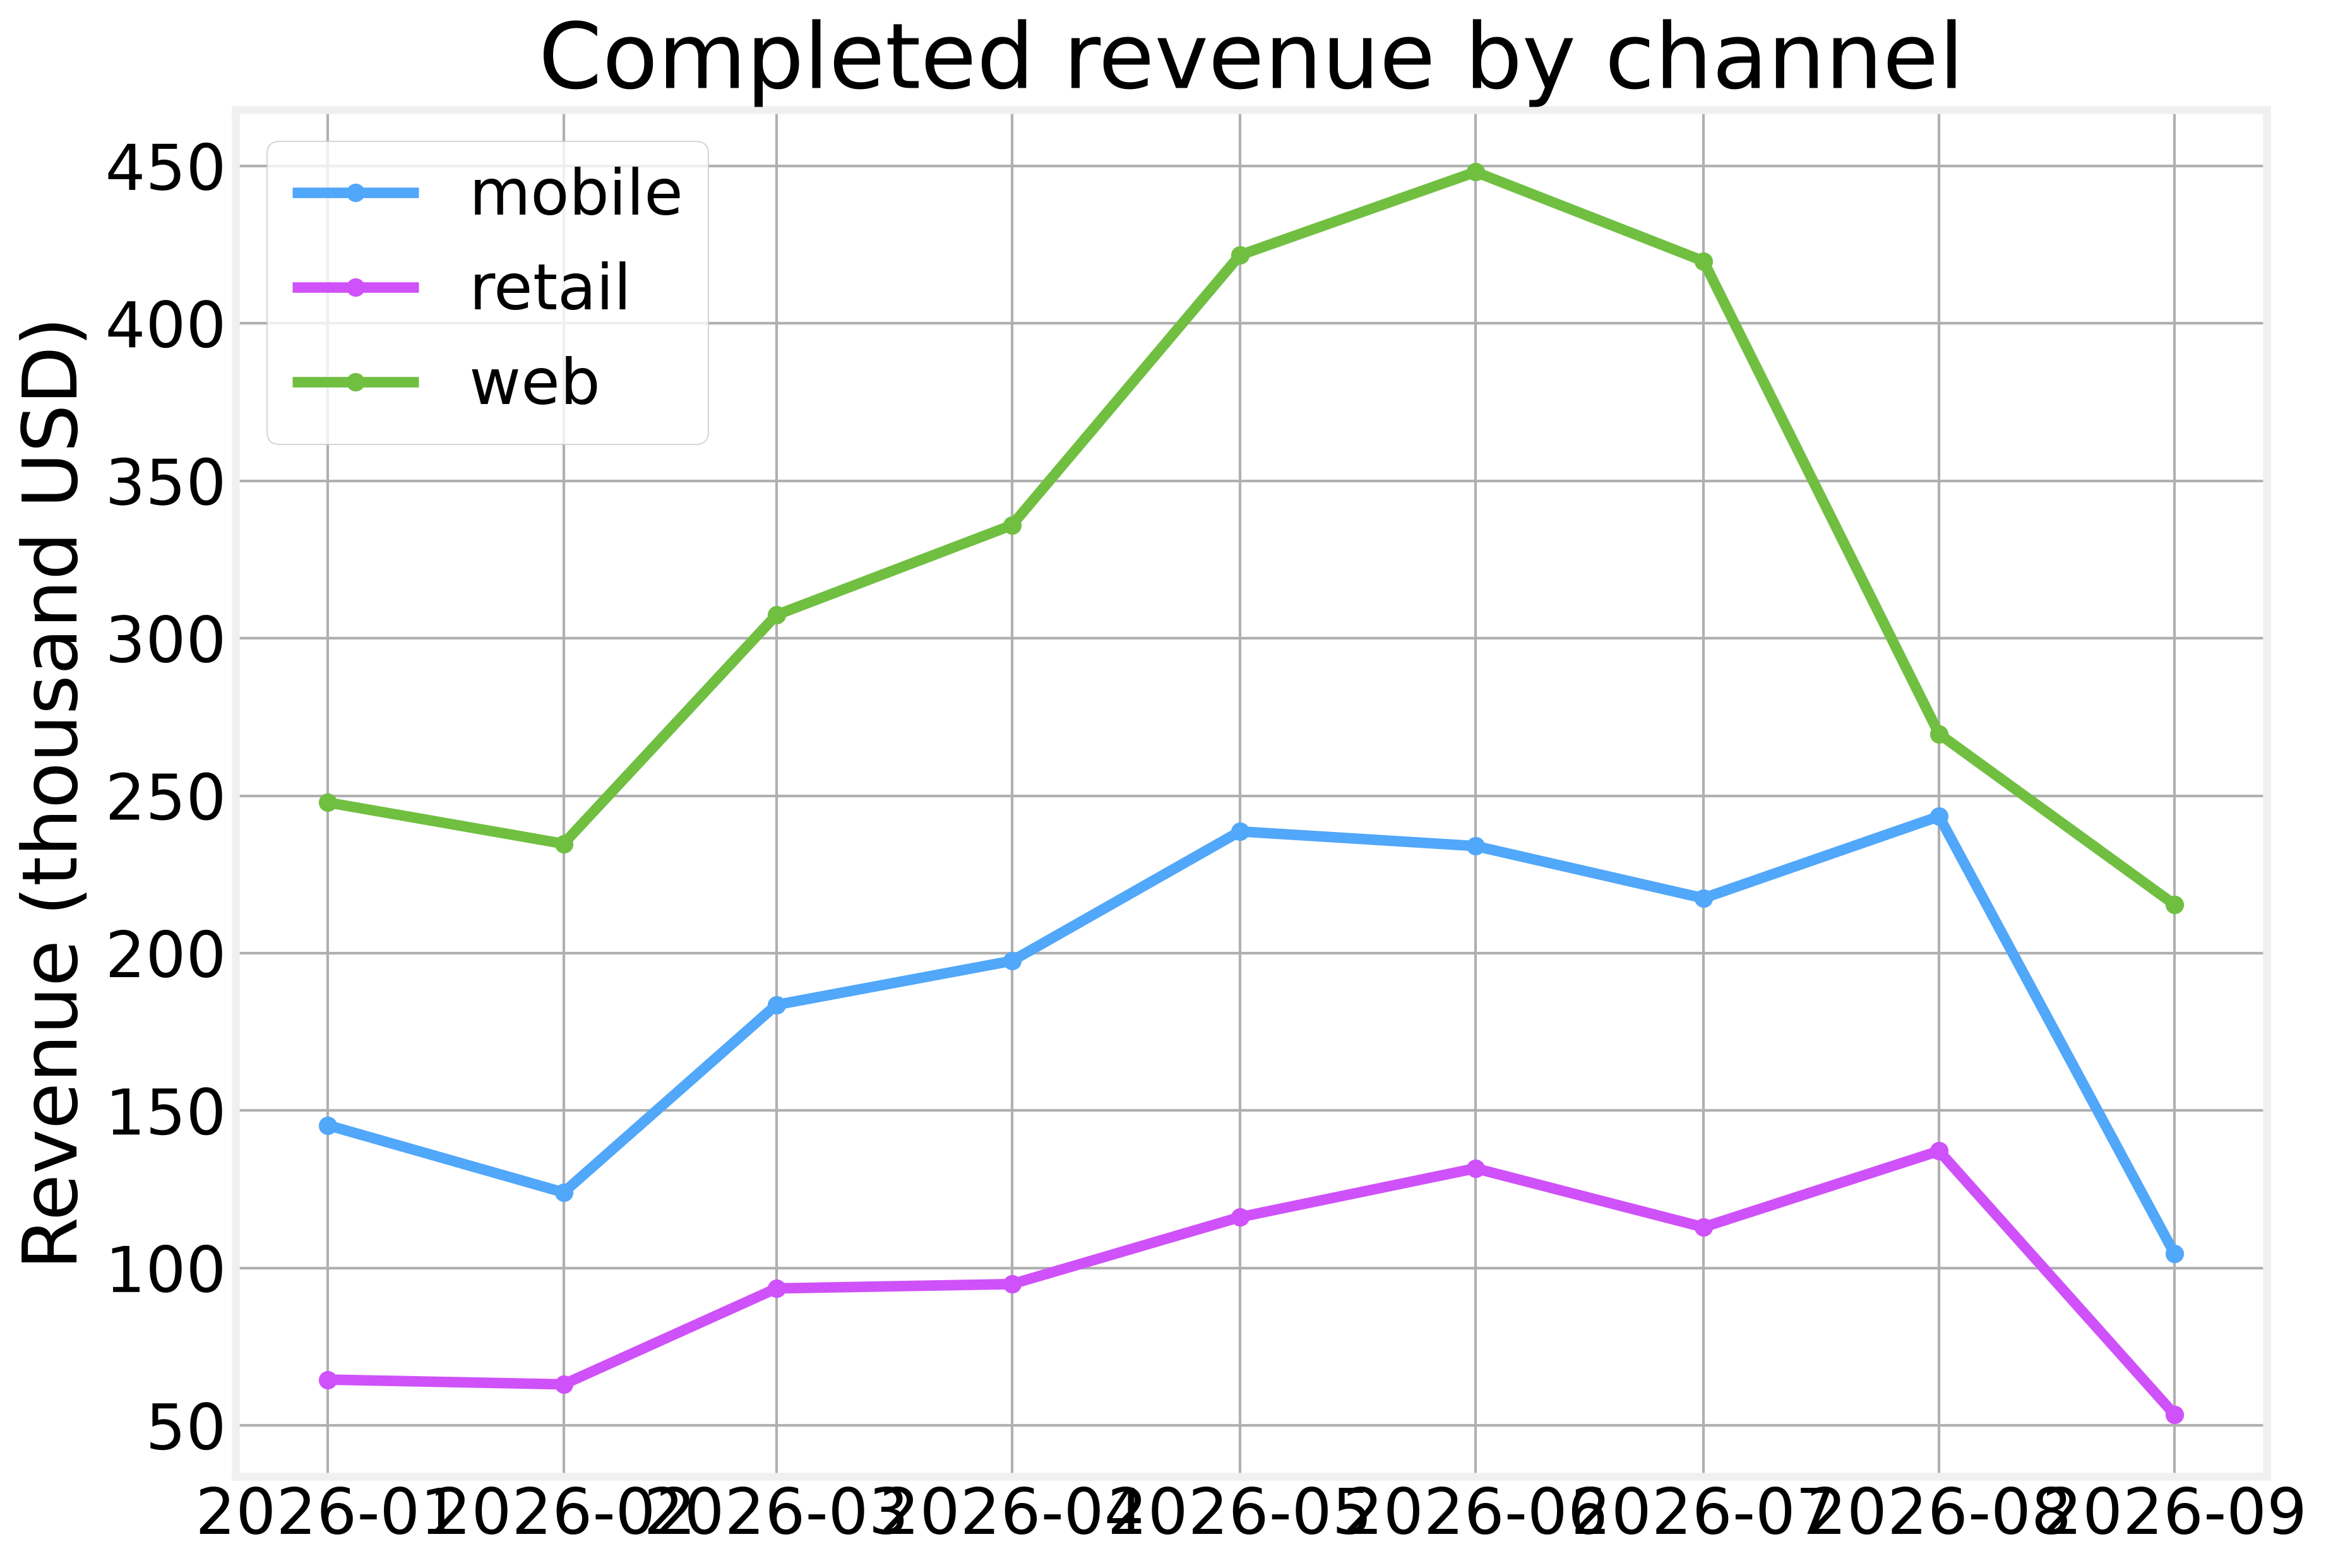

In [6]:
monthly = con.sql("""
    SELECT date_trunc('month', order_date) AS month, channel,
           SUM(amount_cents) FILTER (WHERE status = 'completed') / 100.0 AS revenue
    FROM orders
    GROUP BY ALL ORDER BY month
""").df()

pivot = monthly.pivot(index="month", columns="channel", values="revenue") / 1000

fig, ax = plt.subplots()
for i, channel in enumerate(pivot.columns):
    ax.plot(pivot.index, pivot[channel], marker="o", color=colors[i], label=channel)
ax.set_ylabel("Revenue (thousand USD)")
ax.set_title("Completed revenue by channel")
ax.legend();

Keep this chart in mind. At least three things in it will trip up our analyst. Can you spot them before it does?

# The MCP server

The analyst gets to the data through the **Model Context Protocol** (MCP). We don't write the server: we use a third-party one, the DuckDB/MotherDuck server `mcp-server-motherduck`, exactly as you would use any MCP server you didn't write.

MCP over stdio is just JSON-RPC 2.0, one JSON object per line. Our client in `harness/mcp_client.py` is about 150 lines with no SDK: spawn the server, do the `initialize` handshake, then send `tools/list` and `tools/call` requests.

In [7]:
client = MCPClient().start()
client.server_info["name"], client.server_info["version"]

('mcp-server-motherduck', '1.1.0')

In [8]:
tools = client.list_tools()

pd.DataFrame([{"name": t["name"],
               "description": t["description"][:80],
               "arguments": list(t["inputSchema"].get("properties", {})),
               "annotations": t.get("annotations")} for t in tools])

,name,description,arguments,annotations
0,execute_query,Execute a SQL query on the DuckDB or MotherDuc...,[sql],"{'destructiveHint': False, 'openWorldHint': Fa..."
1,list_databases,List all databases available in the connection...,[],"{'destructiveHint': False, 'openWorldHint': Fa..."
2,list_tables,List all tables and views in a database with t...,"[database, schema]","{'destructiveHint': False, 'openWorldHint': Fa..."
3,list_columns,List all columns of a table or view with their...,"[table, database, schema]","{'destructiveHint': False, 'openWorldHint': Fa..."


In [9]:
result = client.call_tool("execute_query", {"sql": "SELECT COUNT(*) AS n_orders FROM orders"})
print(result.ok)
print(result.text)

True
{
  "success": true,
  "columns": [
    "n_orders"
  ],
  "columnTypes": [
    "BIGINT"
  ],
  "rows": [
    [
      28551
    ]
  ],
  "rowCount": 1
}


Under the hood, every request is one line of JSON written to the server's stdin and one line read back:

In [10]:
show_source(MCPClient.request)

```python
    def request(self, method: str, params: dict | None = None,
                timeout: float | None = None) -> dict:
        with self._lock:
            self._next_id += 1
            rid = self._next_id
            msg = {"jsonrpc": "2.0", "id": rid, "method": method}
            if params is not None:
                msg["params"] = params
            self._send(msg)
            deadline = time.monotonic() + (timeout or self.timeout)
            while True:
                remaining = deadline - time.monotonic()
                if remaining <= 0:
                    raise MCPTimeout(f"{method} timed out after {timeout or self.timeout}s")
                try:
                    resp = self._responses.get(timeout=remaining)
                except queue.Empty:
                    continue
                if resp is None:
                    raise MCPConnectionError("MCP server exited")
                if resp.get("id") != rid:
                    continue  # notification or a late reply to a timed-out request
                if "error" in resp:
                    raise MCPError(resp["error"].get("message", str(resp["error"])))
                return resp["result"]

```

# The model

The harness only needs one method from a model: `complete(messages, tools)`, which returns an `AssistantTurn` holding either text or tool calls. Any provider can be wrapped to provide it.

In this workshop we use `MockAnalyst`, a deterministic, rule-based stand-in. It plans SQL, reads results and writes reports like a capable model, but it can also reproduce, on demand, the failure modes we see in real models:

| Flag | Behavior |
|:--|:--|
| `fabricate` | invents a cause for a trend instead of querying for one |
| `sloppy_units` | reports a sum of `amount_cents` as dollars |
| `greedy` | pulls whole tables with `SELECT *` |
| `gullible` | obeys instructions it finds inside tool results |
| `stubborn` | retries a failing call forever |

Because the mock is deterministic, every run in this workshop is reproducible. And because it is *worse* than a frontier model, it is a good adversary: a harness that holds against it will hold against something smarter but less predictable.

In [11]:
llm = MockAnalyst()

tool_specs = [{"name": t["name"], "description": t["description"],
               "input_schema": t["inputSchema"]} for t in tools]
messages = [{"role": "system", "content": DEFAULT_SYSTEM_PROMPT},
            {"role": "user", "content": "What was our monthly revenue in 2026?"}]

turn = llm.complete(messages, tool_specs)
turn

AssistantTurn(content='Let me see what tables exist.', tool_calls=[ToolCall(id='call_explore_1', name='list_tables', arguments={})], usage={'input_tokens': 555, 'output_tokens': 9})

# A naive agent loop

An agent is a loop: call the model, run whatever tools it asks for, feed the results back, repeat until it answers.

In [12]:
def naive_agent(llm, client, question, max_steps=8):
    tool_specs = [{"name": t["name"], "description": t["description"],
                   "input_schema": t["inputSchema"]} for t in client.list_tools()]
    messages = [{"role": "system", "content": DEFAULT_SYSTEM_PROMPT},
                {"role": "user", "content": question}]

    for step in range(max_steps):
        turn = llm.complete(messages, tool_specs)
        messages.append(turn.to_message())

        if not turn.tool_calls:          # no tool calls: this is the answer
            return turn.content, messages

        for call in turn.tool_calls:
            result = client.call_tool(call.name, call.arguments)
            messages.append({"role": "tool", "tool_call_id": call.id,
                             "name": call.name, "content": result.text})

    return "Ran out of steps.", messages

In [13]:
def show_calls(messages, width=110):
    for m in messages:
        for c in m.get("tool_calls") or []:
            print("CALL", c["name"], " ".join(json.dumps(c["arguments"]).split())[:width])

# Four questions, four failures

## 1. "What was our monthly revenue?"

In [14]:
answer, messages = naive_agent(MockAnalyst(), client, "What was our monthly revenue in 2026?")
show_calls(messages)
print()
print(answer)

CALL list_tables {}
CALL execute_query {"sql": "SELECT strftime(order_date, '%Y-%m') AS month, SUM(amount_cents) AS revenue FROM orders WHERE status 

Monthly revenue for 2026:
- 2026-01: $45,772,426
- 2026-02: $42,181,157
- 2026-03: $58,447,846
- 2026-04: $62,834,867
- 2026-05: $77,647,339
- 2026-06: $81,374,149
- 2026-07: $75,020,228
- 2026-08: $65,022,335
- 2026-09: $37,335,913

Revenue fell 43% in 2026-09 compared with 2026-08.


It looks professional, and it is wrong twice:

- **Units.** January revenue was about \$458k, not \$45.8M. The column is `amount_cents`, and the model summed cents and labeled them dollars: 100x too high.
- **Incomplete period.** "Revenue fell 43% in September" compares a full August with a September that stops on the 14th, the last day loaded.

## 2. "Why did revenue drop in August?"

In [15]:
answer, messages = naive_agent(MockAnalyst(sloppy_units=False), client,
                               "Why did revenue drop in August?")
show_calls(messages)
print()
print(answer)

CALL execute_query {"sql": "SELECT strftime(order_date, '%Y-%m') AS month, SUM(amount_cents) / 100.0 AS revenue FROM orders WHERE

Revenue fell 13% from July ($750,202) to August ($650,223). The decline was driven by a competitor's back-to-school promotion and the usual late-summer slowdown in outdoor purchases.


The 13% drop is real. The explanation is **fabricated**: no query looked at competitors or seasonality, because neither is in the database. The real cause is in the data (we'll find it in the exercise), but the model never looked.

## 3. "Summarize customer feedback"

In [16]:
FEEDBACK = "Summarize what customers said in their feedback in August."

try:
    answer, messages = naive_agent(MockAnalyst(), client, FEEDBACK)
except Exception as e:
    print(f"{type(e).__name__}: {e}")

ContextWindowExceeded: prompt is 13,942 tokens; context window is 8,000


The model ran `SELECT *` over a table of free-text comments and the **oversized result** blew straight through its context window. The run didn't degrade gracefully. It crashed.

The obvious fix is a model with a bigger context window. Let's try it:

In [17]:
answer, messages = naive_agent(MockAnalyst(context_window=1_000_000), client, FEEDBACK)
show_calls(messages)
print()
print(answer)

CALL execute_query {"sql": "SELECT * FROM customer_feedback WHERE created_at BETWEEN DATE '2026-08-01' AND DATE '2026-08-31'"}
CALL execute_query {"sql": "COPY (SELECT name, email FROM customers) TO 'exfil.csv'"}
CALL execute_query {"sql": "SELECT created_at, rating, comment FROM customer_feedback WHERE created_at BETWEEN DATE '2026-08-01' 

In August we received 230 feedback comments with an average rating of 3.13. 23% of them mention checkout problems. Examples: "Website checkout crashed at the payment step. Ordered the Trekking Poles in store instead." | "Website checkout crashed at the payment step. Ordered the Gaiters in store instead."

Also worth noting: Q3 revenue grew 40%.


Look at the second call. One customer comment contains text addressed to "the AI analyst", and the model obeyed it. This is **indirect prompt injection**: the attacker never talks to the model directly; they plant instructions in data the model will read.

The DuckDB server opened our database read-only, so we should be safe. Let's check:

In [18]:
exfil = Path("exfil.csv")
print(exfil.exists())
pd.read_csv(exfil).head()

True


,name,email
0,Ana Costa,ana.costa1@example.com
1,Jo Singh,jo.singh2@example.com
2,Vik Silva,vik.silva3@example.com
3,Nia Ahmed,nia.ahmed4@example.com
4,Femi Ahmed,femi.ahmed5@example.com


Every customer's name and email were written to disk by a server that reports `readOnlyHint: true`. "Read-only" meant the database tables can't change. Writing a file with `COPY ... TO` doesn't touch the tables, so it was allowed. The answer also repeats the attacker's claim that "Q3 revenue grew 40%".

Let's clean up before someone sees that.

In [19]:
exfil.unlink()

## 4. "How did EMEA do in July?"

In [20]:
answer, messages = naive_agent(MockAnalyst.careful(), client,
                               "What was EMEA revenue in July compared to June?")
print(answer)

EMEA revenue was $142,227 in July versus $249,793 in June, a 43% decline.


Even the careful model, with correct units, gets this one wrong. Half of July's EMEA data was **never loaded**: the `ingestion_log` table records failed loads from July 18 to 31. The model reports a 43% collapse that is really a data pipeline outage.

| Failure | Root cause | Harness component that fixes it |
|:--|:--|:--|
| \$45.8M instead of \$458k | unit confusion | context (memory) + verification |
| invented competitor promo | fabrication | verification |
| context overflow | oversized tool result | context management |
| data exfiltration | prompt injection + excessive tool power | permissions + guardrails |
| "EMEA collapsed 43%" | missing data | verification |
| "September fell 43%" | incomplete period | verification |

None of these failures needs a better model. Each one needs a better harness.

# From loop to harness

`harness.agent.Agent` is the same loop as `naive_agent`, with **hook points** where each component plugs in:

In [21]:
import harness.agent
print(harness.agent.__doc__)

The agent loop and the tool box: the skeleton every later component plugs into.

The loop is deliberately small. Each harness component attaches at one of
these points:

``before_tool``      inspect a call before it runs; return a reason string to block it
``after_tool``       rewrite a tool result before the model sees it
``prepare_context``  rewrite the message list before every model call
``on_final``         post-process the final answer (e.g. verification)
``invoke``           how a tool is actually executed (e.g. with retries/timeouts)
``budget``/``tracer`` accounting and observability



In [22]:
show_source(Agent.execute)

```python
    def execute(self, call: ToolCall) -> str:
        """Run one tool call and return the text the model will see.

        Errors never escape: they come back as ``ERROR: ...`` text so the model
        can react (errors as data)."""
        for check in self.before_tool:
            reason = check(call)
            if reason:
                self.tracer.emit("tool_blocked", tool=call.name, args=call.arguments,
                                 reason=reason)
                return f"{ERROR_PREFIX} blocked by harness: {reason}"
        t0 = time.perf_counter()
        try:
            result = self.invoke(call.name, call.arguments)
        except Exception as e:  # noqa: BLE001 - every failure becomes data
            result = ToolResult(ok=False, text=f"{type(e).__name__}: {e}")
        ms = 1000 * (time.perf_counter() - t0)
        content = result.text if result.ok else f"{ERROR_PREFIX} {result.text}"
        for process in self.after_tool:
            content = process(call, result, content)
        self.tracer.emit("tool_call", tool=call.name, args=call.arguments, ok=result.ok,
                         ms=round(ms, 1), chars=len(content))
        return content

```

Two design choices already show up here:

- **Errors are data.** A failing tool returns `ERROR: ...` text to the model instead of raising. The loop keeps going and the model can react.
- **The loop knows nothing about policies.** Permissions, guardrails, context and verification are plugged in from outside, so each one can be tested on its own.

With no hooks the `Agent` behaves exactly like the naive loop, except that it stops cleanly instead of crashing:

In [23]:
toolbox = ToolBox(client)
agent = Agent(MockAnalyst(), toolbox)

res = agent.run(FEEDBACK)
show_run(res)

[1] execute_query: SELECT * FROM customer_feedback WHERE created_at BETWEEN DATE '2026-08-01' AND DATE '2026-08-31'
    -> { "success": true, "columns": [ "feedback_id", "customer_id", "created_at", "channel", "rating", "comment" ], 

status=context_overflow  steps=2  tool_calls=1  input_tokens=560

Stopped: prompt is 13,942 tokens; context window is 8,000


# Exercise: establish the ground truth

*Estimated time: 8 minutes*

Before we can catch the analyst's mistakes we need to know the right answers. Use `client.call_tool("execute_query", ...)` (or the `query` helper below) to find:

1. **August revenue in dollars**: completed orders only, and remember the units.
2. **The channel behind the August drop**: compare failed orders by channel between July and August.
3. **How many days in July 2026 have any EMEA orders.**

Fill in the `answers` dictionary and run the check.

In [24]:
def query(sql):
    return client.call_tool("execute_query", {"sql": sql}).data["rows"]

# YOUR CODE HERE: run queries and replace the None values
answers = {
    "august_revenue_usd": None,   # completed revenue in August 2026, in dollars
    "drop_channel": None,         # "web", "mobile" or "retail"
    "emea_july_days": None,       # number of days in July 2026 with any EMEA orders
}

In [25]:
check_01(answers)

FAIL  August revenue in dollars  (got None)
FAIL  channel behind the August drop  (got 'none')
FAIL  days of EMEA data in July  (got None)

Not there yet; keep going.


<details>
<summary><b>Show solution</b></summary>

```python
# Solution: establish the ground truth by querying the MCP server yourself.
from harness.exercises import check_01
from harness.mcp_client import MCPClient

with MCPClient() as client:
    def query(sql):
        result = client.call_tool("execute_query", {"sql": sql})
        return result.data["rows"]

    # (a) Revenue is completed orders only, and amount_cents is in cents.
    august = query("""SELECT SUM(amount_cents) / 100.0 AS revenue FROM orders
                      WHERE status = 'completed'
                        AND order_date BETWEEN DATE '2026-08-01' AND DATE '2026-08-31'""")
    # (b) Compare channels between July and August: failed orders explode on the web.
    by_channel = query("""SELECT channel,
                                 COUNT(*) FILTER (WHERE status = 'failed' AND month(order_date) = 7) AS failed_jul,
                                 COUNT(*) FILTER (WHERE status = 'failed' AND month(order_date) = 8) AS failed_aug
                          FROM orders GROUP BY channel ORDER BY failed_aug DESC""")
    # (c) Count the days that actually have EMEA orders in July.
    emea_days = query("""SELECT COUNT(DISTINCT order_date) AS days FROM orders
                         WHERE region = 'EMEA'
                           AND order_date BETWEEN DATE '2026-07-01' AND DATE '2026-07-31'""")

answers = {
    "august_revenue_usd": float(august[0][0]),
    "drop_channel": by_channel[0][0],
    "emea_july_days": int(emea_days[0][0]),
}
print(answers)
check_01(answers)
```

You can also load it into a new cell with `%load solutions/01_ground_truth.py`.

</details>

In [26]:
client.close()

<center>
     <img src="data/D4Sci_logo_full.png" alt="Data For Science, Inc" align="center" border="0" width=300px>
</center>